# Decision boundaries, trees, and random forests

In lecture 11 we predicted the `grass` using `educ`. In lecture 12 we added a predictor. 

Today we explore how we to visualize two predictors in one chart and add a try multiple predictors with a logistic regression model.


## Setup

In [1]:
library('tidymodels')

options(repr.plot.res = 250, repr.plot.height = 3, repr.plot.width = 5)

── Attaching packages ────────────────────────────────────────────────────────────────────────────────────── tidymodels 1.4.1 ──
✔ broom        1.0.13     ✔ recipes      1.4.0 
✔ dials        1.4.4      ✔ rsample      1.3.2 
✔ dplyr        1.2.1      ✔ tailor       0.1.0 
✔ ggplot2      4.0.3      ✔ tidyr        1.3.2 
✔ infer        1.1.0      ✔ tune         2.1.0 
✔ modeldata    1.6.0      ✔ workflows    1.3.0 
✔ parsnip      1.6.1      ✔ workflowsets 1.1.1 
✔ purrr        1.2.2      ✔ yardstick    1.4.0 
── Conflicts ───────────────────────────────────────────────────────────────────────────────────────── tidymodels_conflicts() ──
✖ tidyr::complete() masks hera::complete()
✖ purrr::discard()  masks scales::discard()
✖ dplyr::filter()   masks stats::filter()
✖ dplyr::lag()      masks stats::lag()
✖ recipes::step()   masks stats::step()
• Use suppressPackageStartupMessages() to eliminate package startup messages


## The data

Load the GSS data set. Make `yes` (1 or 0) and `grass_f` (a factor), like in lecture 11.

In [2]:
gss = read.csv('https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/gss_subset.csv')

gss_grass <- gss |>
    drop_na(educ, grass) |>
    mutate(
        yes = if_else(grass == 1, 1, 0),
        grass_f = factor(grass, levels = c(2, 1), labels = c('no', 'yes'))
    )

gss_grass |> count(grass_f)

  grass_f n    
1 no      26198
2 yes     13243

## A second predictor: `year`

The GSS asked the `grass` question for the years 1973 to 2024. Let's chart the fraction of yes responders over time.

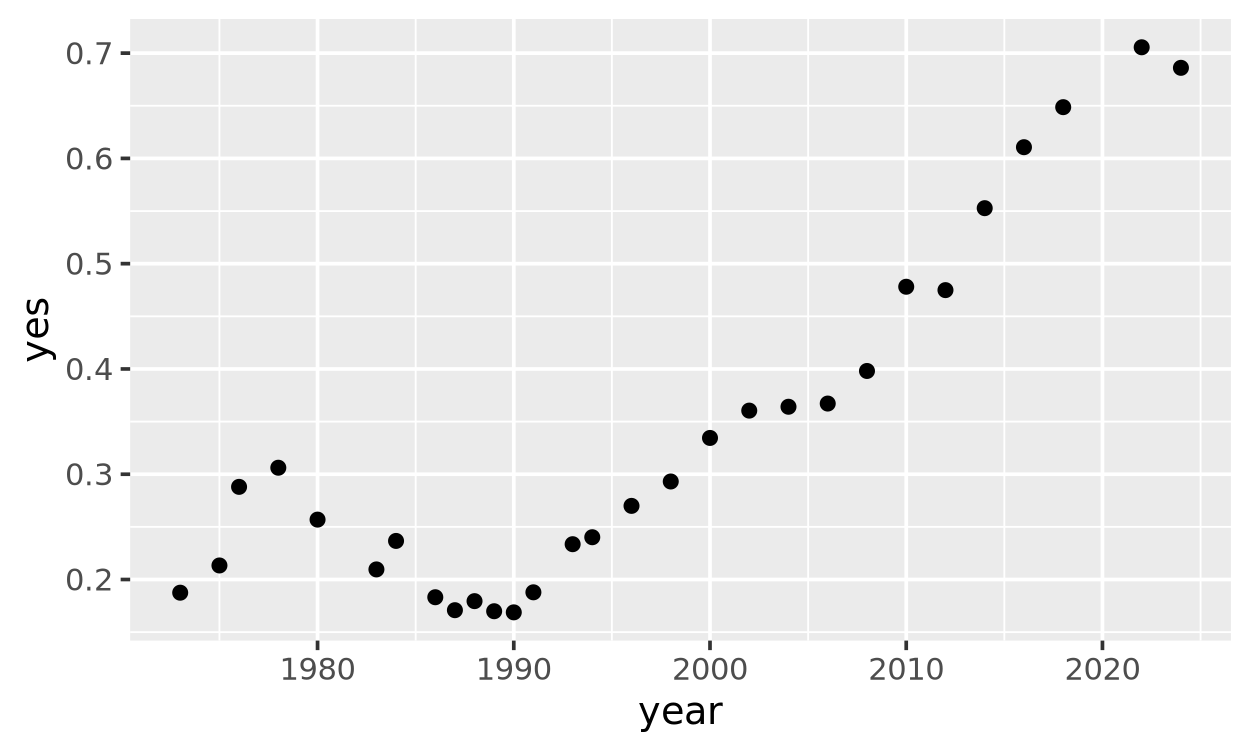

In [3]:
grass_by_year <- gss_grass |>
    group_by(year) |>
    summarize(yes = mean(yes))

p_year <- ggplot(grass_by_year, aes(x = year, y = yes)) +
    geom_point()

p_year

A big change! About 0.2 said yes in the 1970s. About 0.7 said yes in the 2020s.

Look at the 1980s. The share goes **down** for a while. Then it goes up again. Keep this dip in mind.

## Logistic regression with two predictors

Put `year` in the formula with a `+`, like in lecture 12:

$$ p = \text{inv\_logit}(a_1 + a_2 \times \text{educ} + a_3 \times \text{year}) $$

In [4]:
fit_logit <- logistic_reg() |> fit(grass_f ~ educ + year, data = gss_grass)

tidy(fit_logit)

  term        estimate     std.error    statistic p.value      
1 (Intercept) -85.82787294 1.6249487532 -52.81882  0.000000e+00
2 educ          0.09049678 0.0037842855  23.91383 2.198961e-126
3 year          0.04203240 0.0008156218  51.53418  0.000000e+00

Both slopes are positive. More education goes with more yes. A later year goes with more yes.

Look at the predictions. Make a grid with every year, for two education levels: 12 years (high school) and 16 years (bachelor's).

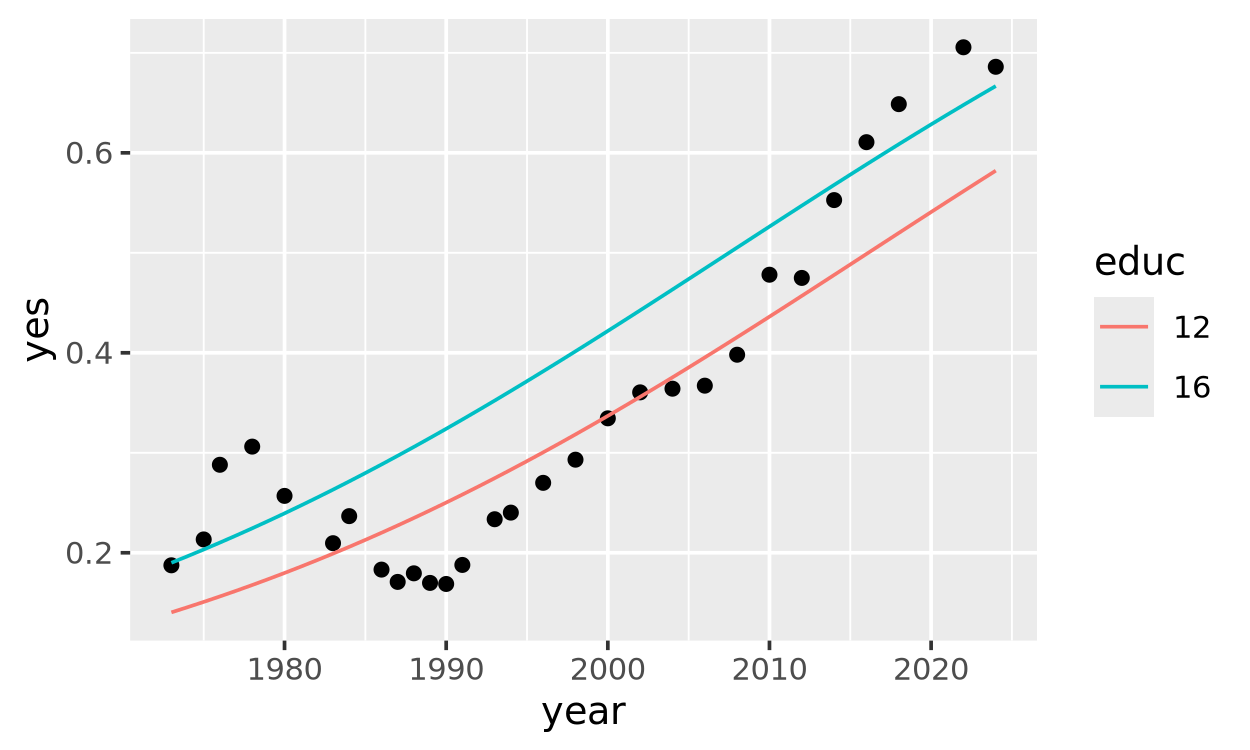

In [5]:
grid_year <- crossing(year = 1973:2024, educ = c(12, 16))

preds_year <- fit_logit |>
    predict(new_data = grid_year, type = 'prob') |>
    bind_cols(grid_year)

p_year +
    geom_line(data = preds_year, aes(y = .pred_yes, color = factor(educ))) +
    labs(color = 'educ')

Two curves that go up. The `educ = 16` curve is above the `educ = 12` curve.

The curves go up the whole time. They **cannot** show the dip in the 1980s. The model family only lets the curve go up (or only down).

## From a probability to a yes/no answer

The model returns a **probability**. But sometimes we want **yes or no**. For example: "Do we think this person will say yes?"

Let's look at the probability of yes for six people:

In [6]:
set.seed(1)

six <- gss_grass |>
    slice_sample(n = 6) |>
    select(educ, year, grass_f)

preds_six <- fit_logit |>
    predict(new_data = six, type = 'prob') |>
    bind_cols(six)

preds_six

  .pred_no  .pred_yes educ year grass_f
1 0.6630928 0.3369072 12   2000 yes    
2 0.8857324 0.1142676  8   1976 no     
3 0.7473574 0.2526426 14   1986 no     
4 0.5781346 0.4218654 16   2000 yes    
5 0.4320890 0.5679110 16   2014 no     
6 0.8104577 0.1895423  9   1988 no     

Now make a rule: **if the probability of yes is more than 0.5, guess yes. If not, guess no.**

`if_else()` does this.

In [7]:
preds_six <- preds_six |>
    mutate(guess = if_else(.pred_yes > 0.5, 'yes', 'no'))

preds_six

  .pred_no  .pred_yes educ year grass_f guess
1 0.6630928 0.3369072 12   2000 yes     no   
2 0.8857324 0.1142676  8   1976 no      no   
3 0.7473574 0.2526426 14   1986 no      no   
4 0.5781346 0.4218654 16   2000 yes     no   
5 0.4320890 0.5679110 16   2014 no      yes  
6 0.8104577 0.1895423  9   1988 no      no   

Compare `guess` with `grass_f`. Some guesses are right. Some are wrong.

tidymodels can do this for you. Use `type = 'class'` in `predict()`. It gives `.pred_class`.

In [8]:
fit_logit |>
    predict(new_data = six, type = 'class') |>
    bind_cols(preds_six |> select(.pred_yes, guess))

  .pred_class .pred_yes guess
1 no          0.3369072 no   
2 no          0.1142676 no   
3 no          0.2526426 no   
4 no          0.4218654 no   
5 yes         0.5679110 yes  
6 no          0.1895423 no   

`.pred_class` and `guess` are the same. So `type = 'class'` is just our 0.5 rule.

### The threshold is a choice

The 0.5 is called the **threshold**. It is not a law. We can pick a different number.

Use all the people. Try a threshold of 0.5 and a threshold of 0.3. For each, find:

- `share_yes`: the share of people we guess yes for.
- `accuracy`: the share of people we guess right.

`guess == grass_f` is `TRUE` when the guess is right. The mean of `TRUE`/`FALSE` is the share of `TRUE`.

In [9]:
preds_all <- fit_logit |>
    predict(new_data = gss_grass, type = 'prob') |>
    bind_cols(gss_grass)

preds_all |>
    mutate(
        guess_50 = if_else(.pred_yes > 0.5, 'yes', 'no'),
        guess_30 = if_else(.pred_yes > 0.3, 'yes', 'no')
    ) |>
    summarize(
        share_yes_50 = mean(guess_50 == 'yes'),
        accuracy_50  = mean(guess_50 == grass_f),
        share_yes_30 = mean(guess_30 == 'yes'),
        accuracy_30  = mean(guess_30 == grass_f)
    )

  share_yes_50 accuracy_50 share_yes_30 accuracy_30
1 0.1748434    0.7061687   0.53059      0.604726   

With 0.5, we guess yes for about 17% of people. We are right about 71% of the time.

With 0.3, we guess yes for about 53% of people. We catch more of the yes people, but we are right only about 60% of the time.

A lower threshold says yes more often. Which threshold is best depends on the implications of a wrong guess. Today we stick to 0.5.

### Is 71% good?

Here is a lazy rule: **always guess no**. How often is it right?

In [10]:
gss_grass |> summarize(accuracy_always_no = mean(grass_f == 'no'))

  accuracy_always_no
1 0.6642327         

About 66%! Most people said no, so "always no" is right most of the time. Our model is better, but only by about 5 points.

**Always compare accuracy simple naive model!**

## The decision boundary

Every combination of `educ` and `year` gets a probability and our threshod setting translates the probability into yes or no.

The **decision boundary** is the line that divides yes from no. On the line, the probability is exactly 0.5.

To draw a decision boundary make predictons for a grid or `educ` and  `year`values. Then color each tiles on a chart based on the predictions.

In [11]:
grid <- crossing(educ = 0:20, year = 1973:2024)

grid |> head()

  educ year
1 0    1973
2 0    1974
3 0    1975
4 0    1976
5 0    1977
6 0    1978

We will reuse this chart later for other models, so let's write a re-usable function. The function makes a 2D chart taht colors each square by `.pred_yes`:

- blue: probability of yes is low (guess no)
- white: probability is near 0.5
- orange: probability of yes is high (guess yes)

`geom_contour()` draws a black line where the probability is 0.5: the decision boundary.

In [12]:
plot_boundary <- function(fit, grid) {
    preds <- fit |>
        predict(new_data = grid, type = 'prob') |>
        bind_cols(grid)

    ggplot(preds, aes(x = year, y = educ)) +
        geom_tile(aes(fill = .pred_yes)) +
        geom_contour(aes(z = .pred_yes), breaks = 0.5, color = 'black') +
        scale_fill_gradient2(low = 'steelblue', mid = 'white', high = 'darkorange',
                             midpoint = 0.5, limits = c(0, 1))
}

### First, the real answers

Before we look at a model let's chart how people **actually** responded: the **proportion yes** (the proportion of people who said yes) at each `educ` and `year`. We will use use the same colors, so we can compare this chart with each model chart.

Some squares have only a few people, so their proportion jumps around is noisy. To mitigate this we will keep squares with 10 or more people.

The gray vertical strptes are years were the GSS survey was not conducted.

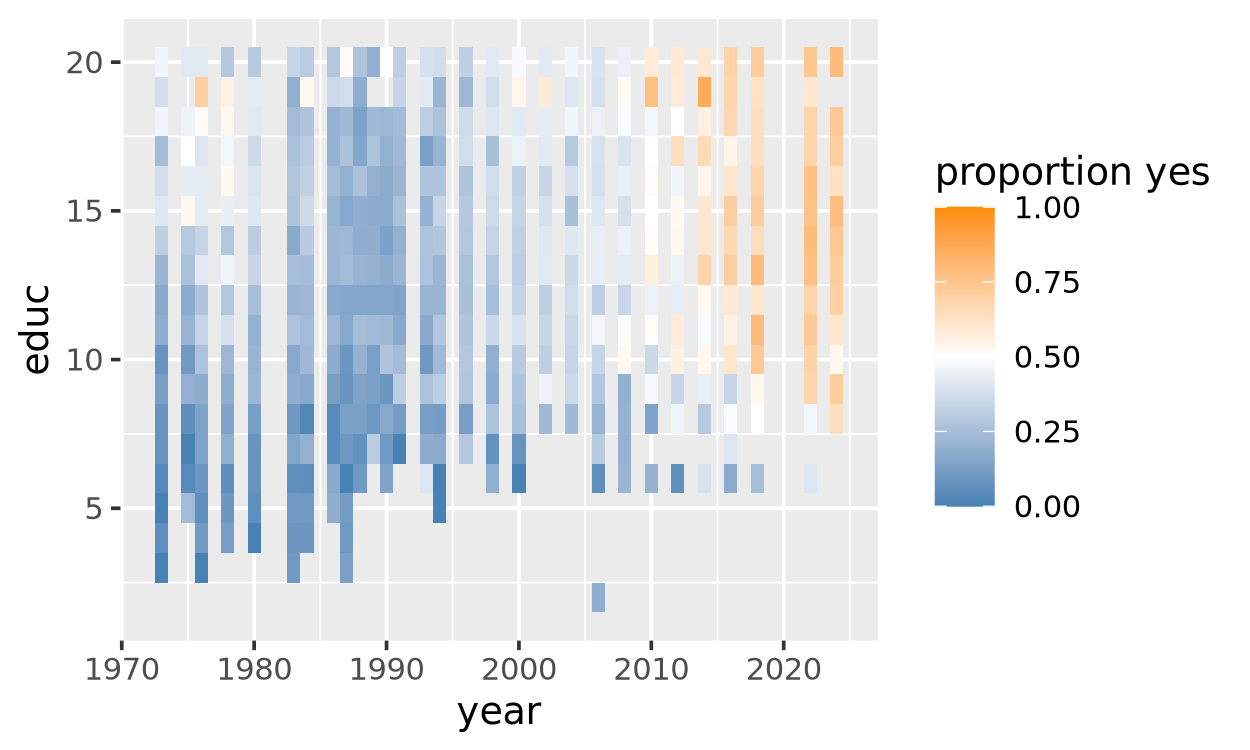

In [13]:
actual_yes <- gss_grass |>
    group_by(educ, year) |>
    summarize(prop_yes = mean(yes), n = n(), .groups = 'drop') |>
    filter(n >= 10)

p_actual <- ggplot(actual_yes, aes(x = year, y = educ)) +
    geom_tile(aes(fill = prop_yes)) +
    scale_fill_gradient2(low = 'steelblue', mid = 'white', high = 'darkorange',
                         midpoint = 0.5, limits = c(0, 1)) +
    labs(fill = 'proportion yes')

p_actual

You can see the 1980s dip: the blue gets darker. After about 2010, most squares are orange.

Keep this chart in mind. For each model below, scroll back and compare. Does the model's chart look like this one?

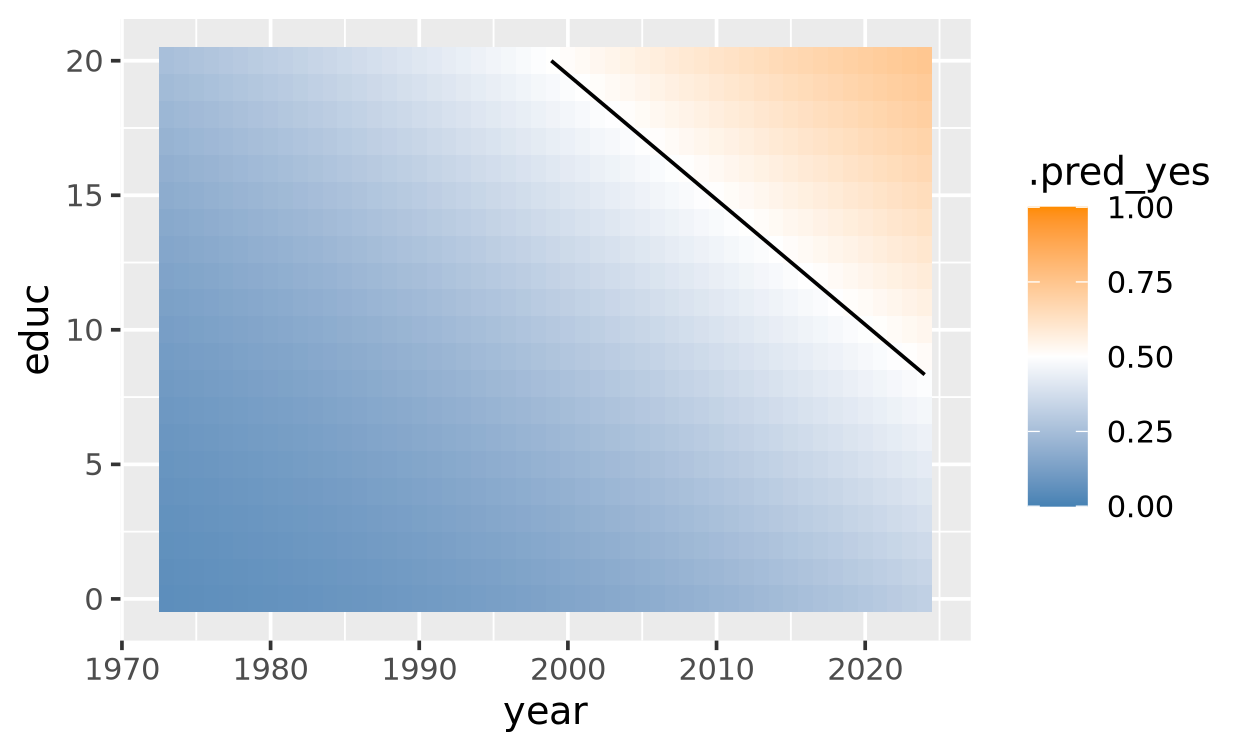

In [14]:
plot_boundary(fit_logit, grid)

The boundary is a **straight line**. Above and to the right (more school, later year), we guess yes. Everywhere else, we guess no.

Compare this chart to `p_actual`...

### Why a straight line?

`inv_logit()` gives 0.5 when its input is 0. So the boundary is where:

$$ a_1 + a_2 \times \text{educ} + a_3 \times \text{year} = 0 $$

Solve for `educ`:

$$ \text{educ} = -\frac{a_1}{a_2} - \frac{a_3}{a_2} \times \text{year} $$

That is a line, with intercept $-a_1/a_2$ and slope $-a_3/a_2$. Draw it in red over the plot.

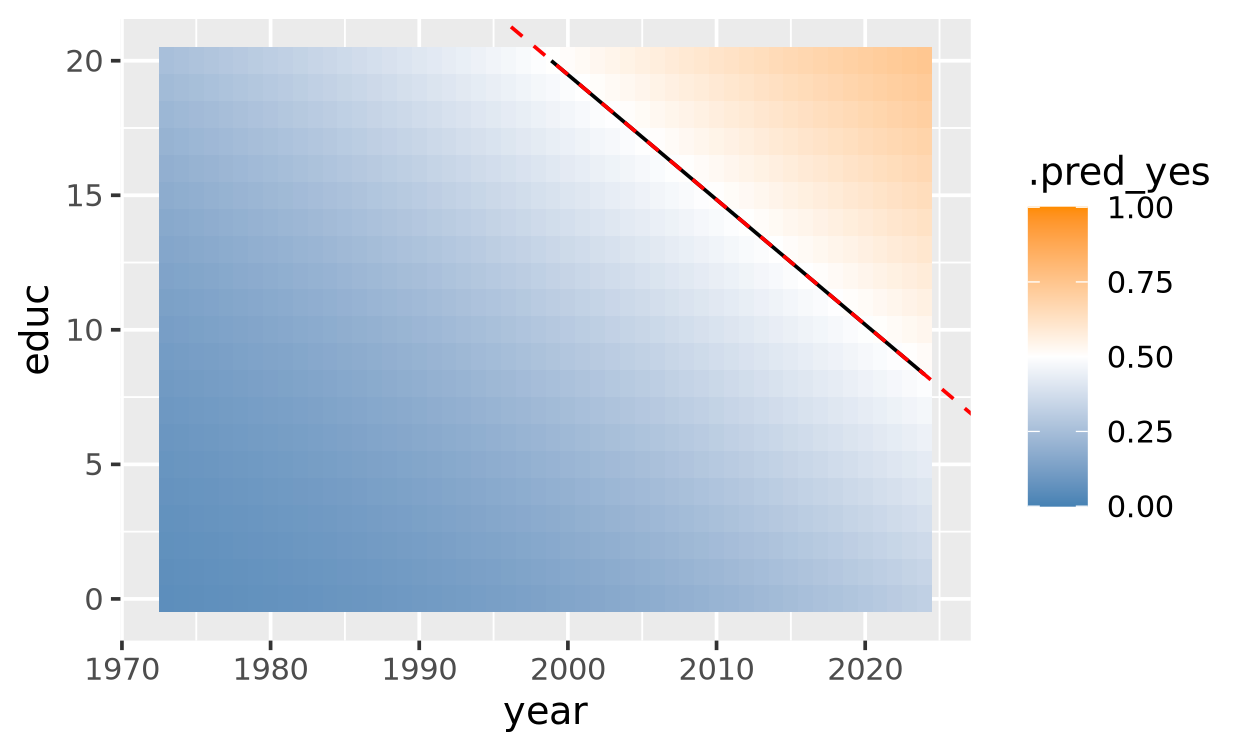

In [15]:
a <- tidy(fit_logit)$estimate

plot_boundary(fit_logit, grid) +
    geom_abline(intercept = -a[1] / a[2], slope = -a[3] / a[2], color = 'red', linetype = 'dashed')

The red line is on top of the black line.

For logistic regression, the decision boundary is a straight line. If the real boundary has a more complex shape, this kind of model cannot model it very well.

## A decision tree

A **decision tree** is a different model family. It asks yes/no questions, one after the other. For example: "Is `year` 2009 or later?" Each answer sends you down a path or branch in a "tree". At the end tips of the tree (the **leaves**), you get a probability.

tidymodels fits a tree with `decision_tree()`.

- `tree_depth = 3`: ask at most 3 questions.
- `cost_complexity = 0.001`: a small number lets the tree make small splits. (With the default, this tree stops after 1 question.)
- `set_mode('classification')`: the outcome is a category, not a number.

In [16]:
fit_tree <- decision_tree(tree_depth = 3, cost_complexity = 0.001) |>
    set_mode('classification') |>
    fit(grass_f ~ educ + year, data = gss_grass)

Draw the tree. `extract_fit_engine()` gets the model out of the tidymodels wrapper. `rpart.plot()` draws it.

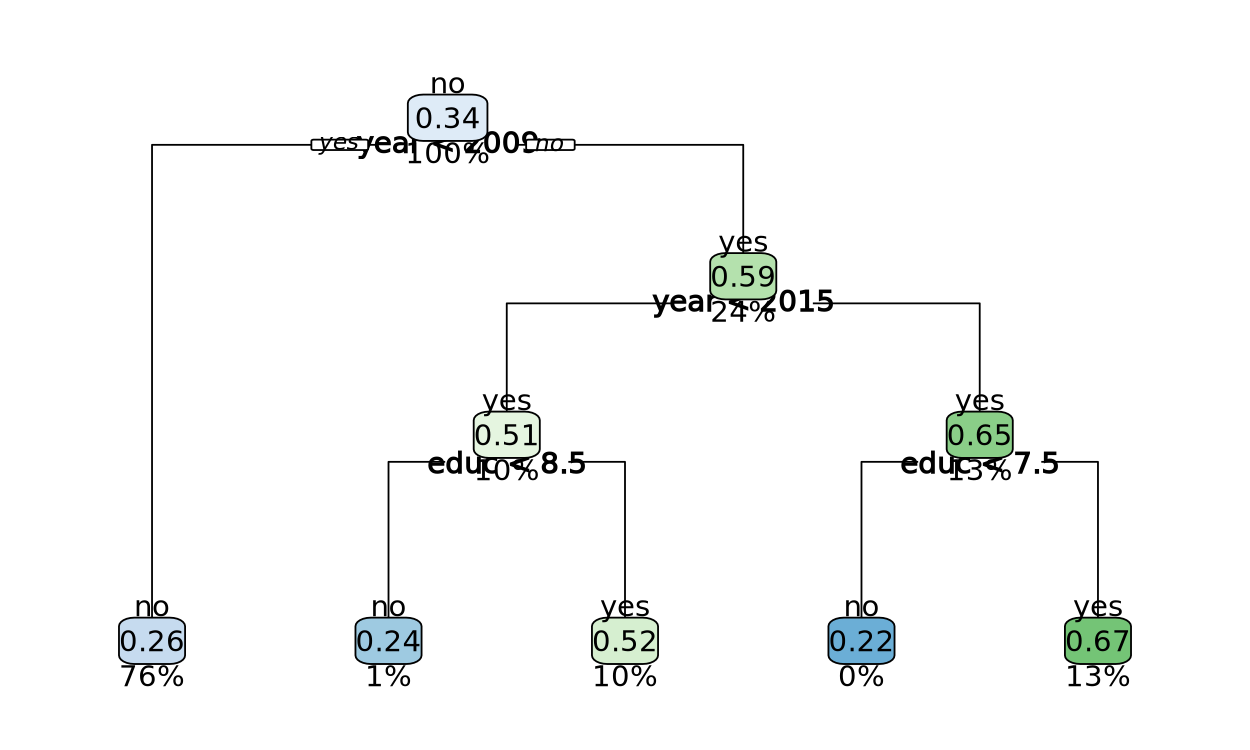

In [17]:
fit_tree |>
    extract_fit_engine() |>
    rpart.plot::rpart.plot(roundint = FALSE, cex = 0.7)

How to read a box:

- top line: the guess (`no` or `yes`)
- middle line: the probability of yes
- bottom line: the percent of all people in this box

The question is under each box. Go left if the answer is **yes**. Go right if it is **no**.

Try one person: `educ = 16`, `year = 2012`.

1. `year < 2009`? No. Go right.
2. `year < 2015`? Yes. Go left.
3. `educ < 8.5`? No. Go right.

We end in a leaf with probability 0.52. That is more than 0.5, so the guess is yes.

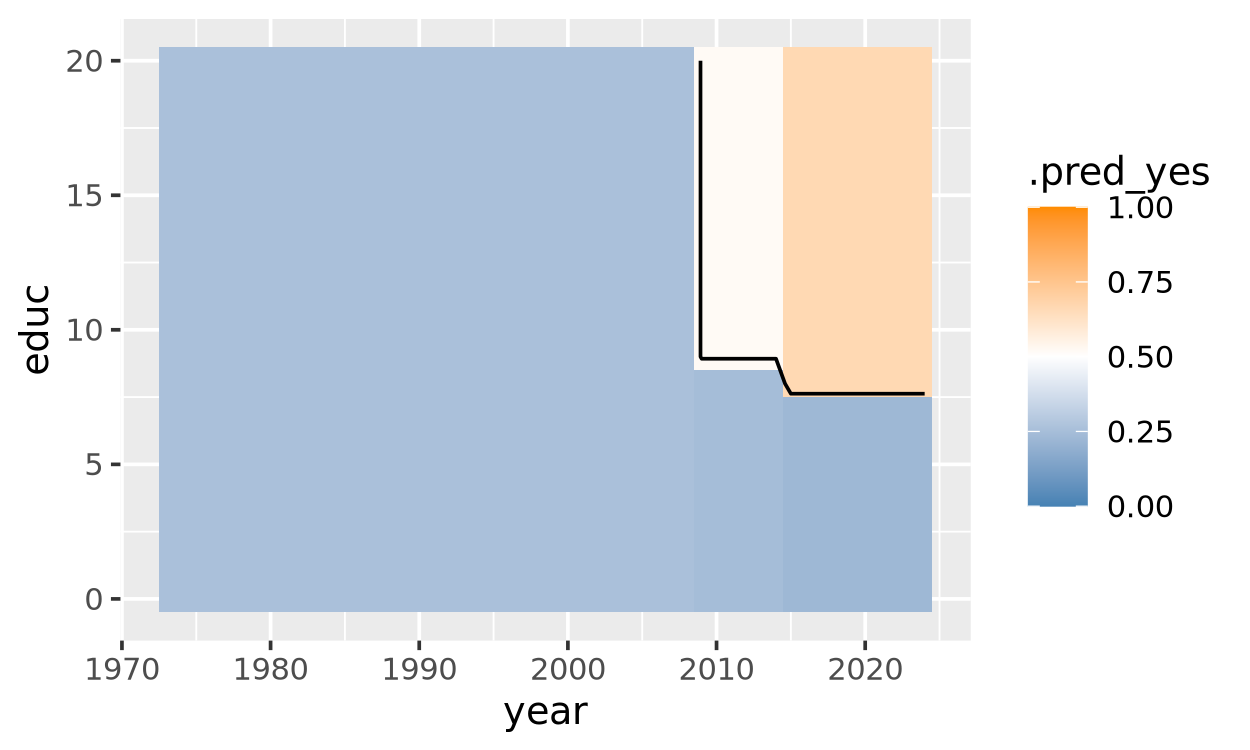

In [18]:
plot_boundary(fit_tree, grid)

The tree cuts the plot into **boxes**. Every cut is a straight line, up-and-down or side-to-side. Inside a box, every person gets the same probability.

The boundary is no longer one straight line. It is a staircase.

## A random forest

One tree is simple, but it is rough. A **random forest** is a way to combine the predictions of many trees.

Each tree is a little different:

- Each tree sees a random sample of the people (some people two times, some not at all).
- At each split, each tree can use only some of the predictors, chosen at random.

The predicted probability from the "forest" is the mean prediction over all the trees.

tidymodels fits it with `rand_forest()`. `trees = 200` grows 200 trees. A forest is random, so we use `set.seed()` to get the same answer each time.

In [19]:
set.seed(512)

fit_rf <- rand_forest(trees = 200) |>
    set_mode('classification') |>
    set_engine('ranger') |>
    fit(grass_f ~ educ + year, data = gss_grass)

fit_rf

parsnip model object

Ranger result

Call:
 ranger::ranger(x = maybe_data_frame(x), y = y, num.trees = 200,      num.threads = 1, verbose = FALSE, seed = sample.int(10^5,          1), probability = TRUE) 

Type:                             Probability estimation 
Number of trees:                  200 
Sample size:                      39441 
Number of independent variables:  2 
Mtry:                             1 
Target node size:                 10 
Variable importance mode:         none 
Splitrule:                        gini 
OOB prediction error (Brier s.):  0.193952 

A forest also gives a probability with `type = 'prob'`. And `type = 'class'` uses the same 0.5 rule.

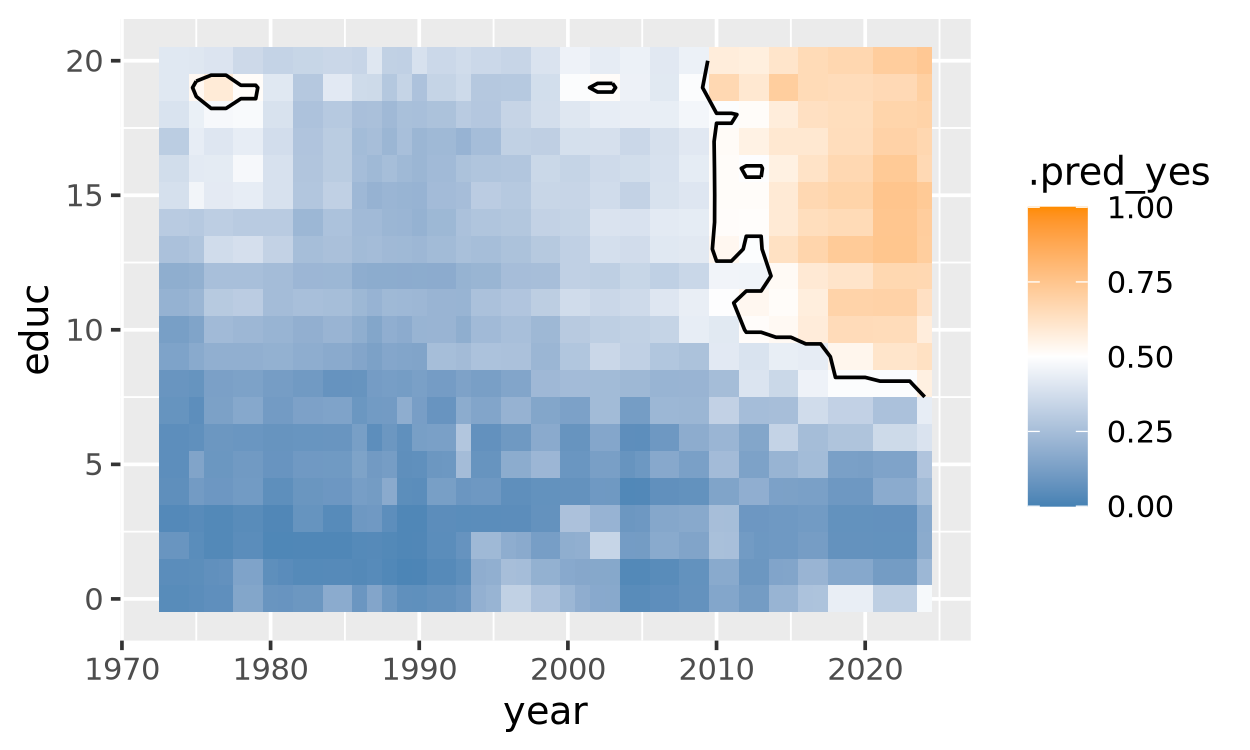

In [20]:
plot_boundary(fit_rf, grid)

Now the boxes are much smaller. Look at the colors:

- Look at the 1970s and the 1980s. The blue gets darker from the late 1970s to the late 1980s. That is the dip. Logistic regression could not show it.
- The black line is not straight. After 2010, people with less school still mostly say no.
- There are small islands, like at `educ = 19` in the late 1970s. Few people are in those squares, so these islands may be **noise**, not a real pattern.

A forest can follow almost any shape. That is good when the shape is real, and bad when it follows noise.

Now flip back to `p_actual`. The forest chart looks much more like the real answers: the dip in the 1980s, and orange starting at about 2010. The logistic chart could not make either shape.

The forest also copies some of the noise. The small islands are squares where only a few people answered.

## Compare the models

Find the accuracy of each model.

In [21]:
accuracy_of <- function(fit) {
    pred <- predict(fit, new_data = gss_grass, type = 'class')$.pred_class
    mean(pred == gss_grass$grass_f)
}

tibble(
    model = c('always no', 'logistic', 'tree', 'forest'),
    accuracy = c(mean(gss_grass$grass_f == 'no'),
                 accuracy_of(fit_logit), accuracy_of(fit_tree), accuracy_of(fit_rf))
)

  model     accuracy 
1 always no 0.6642327
2 logistic  0.7061687
3 tree      0.7112396
4 forest    0.7154737

All three models are close: about 71%. The forest is a little better.

**Be careful:** we measured accuracy on the same people we used to fit the models. A forest can memorize noise, so measuring accuracy in this way can inflate our evaluation of the model's performance.